In [12]:
import altair as alt
import numpy as np
import pandas as pd
from anndata import AnnData
alt.data_transformers.enable("vegafusion")
alt.renderers.enable('png')

def compare_spatial(
    real_adata: AnnData,
    simulator,
    gene: str,
    spatial1: str = "spatial1",
    spatial2: str = "spatial2",
    width: int = 300,
    height: int = 300,
    point_size: int = 8,
    opacity: float = 0.6,
    color_scheme: str = "viridis",
) -> alt.Chart:
    """Faceted real vs. simulated log-count scatter plot for a given gene.
    Examples
    --------
    >>> from scdesigner.utils.plotting import compare_real_vs_simulated
    >>> chart = compare_real_vs_simulated(sce, sim, "Gm42418")
    >>> chart.show()
    """
    # --- real data ---
    real_df = real_adata.obs[[spatial1, spatial2]].copy()
    real_counts = real_adata[:, gene].X.toarray().flatten()
    real_df["log_count"] = np.log1p(real_counts)
    real_df["source"] = "real"

    # --- simulated data ---
    sim_adata = simulator.sample()
    sim_df = sim_adata.obs[[spatial1, spatial2]].copy()
    sim_counts = sim_adata[:, gene].X.toarray().flatten()
    sim_df["log_count"] = np.log1p(sim_counts)
    sim_df["source"] = "simulated"

    # --- combine ---
    df = pd.concat([real_df, sim_df], ignore_index=True)

    # --- plot ---
    chart = (
        alt.Chart(df, width=width, height=height)
        .mark_point(size=point_size, opacity=opacity)
        .encode(
            x=alt.X(f"{spatial1}:Q", title="Spatial 1"),
            y=alt.Y("log_count:Q", title=f"log(1 + count) — {gene}"),
            color=alt.Color(
                f"{spatial2}:Q",
                title="Spatial 2",
                scale=alt.Scale(scheme=color_scheme),
            ),
        )
        .facet(column=alt.Column("source:N", title=None))
    )
    return chart

In [13]:
from scdesigner.simulators import SpatialNegBinCopula, PenalizedNegBinCopula
from scdiagnostics.marginal import compare_moments

Epoch 171/200, Loss: 1.8972, Val Loss: 1.8736


Estimating copula correlation: 100%|██████████| 4/4 [00:04<00:00,  1.23s/it]


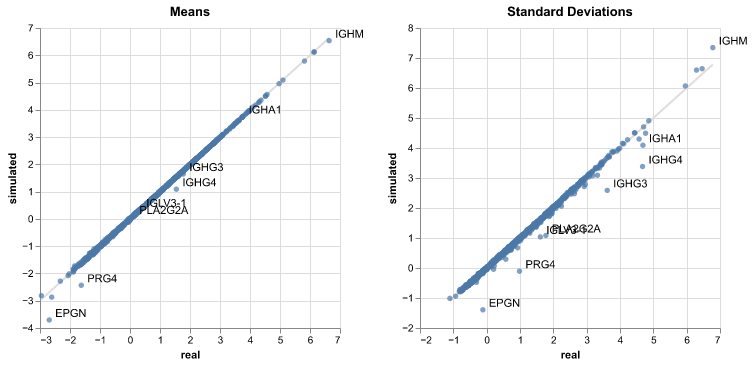

In [14]:
from scdesigner.datasets import ovarian

sce = ovarian()
sim = PenalizedNegBinCopula("~ cell_type")
sim.fit(sce, max_epochs=200)
compare_moments(sce, sim.sample(), label_threshold=0.5)

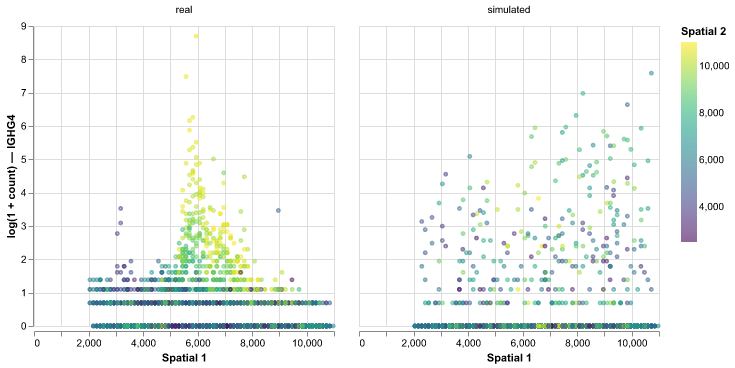

In [15]:
compare_spatial(sce, sim, "IGHG4")

Epoch 21/200, Loss: 1.8694, Val Loss: 1.8508


Estimating copula correlation: 100%|██████████| 4/4 [00:23<00:00,  5.92s/it]


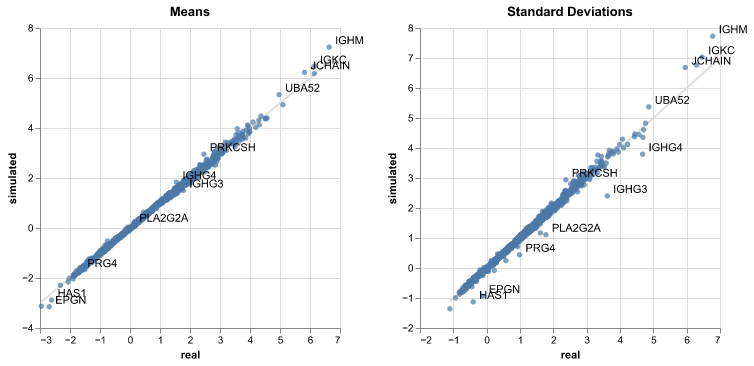

In [16]:
sim = SpatialNegBinCopula("~ 0 + cell_type", "~ 0 + cell_type", basis="tps", disp_df=5)
sim.fit(sce, max_epochs=200)
compare_moments(sce, sim.sample(), label_threshold=0.5)

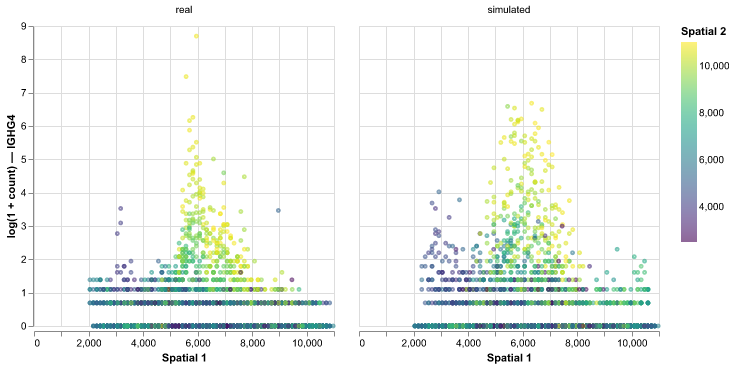

In [17]:
compare_spatial(sce, sim, "IGHG4")

In [18]:
from scdesigner.datasets import visium

sce = visium()
sim = SpatialNegBinCopula("~ 0 + cell_type", "~ 0 + cell_type", basis="tps", disp_df=5)
sim.fit(sce,  max_epochs = 200)

Epoch 28/200, Loss: 1.7555, Val Loss: 1.7529


Estimating copula correlation: 100%|██████████| 3/3 [00:12<00:00,  4.27s/it]


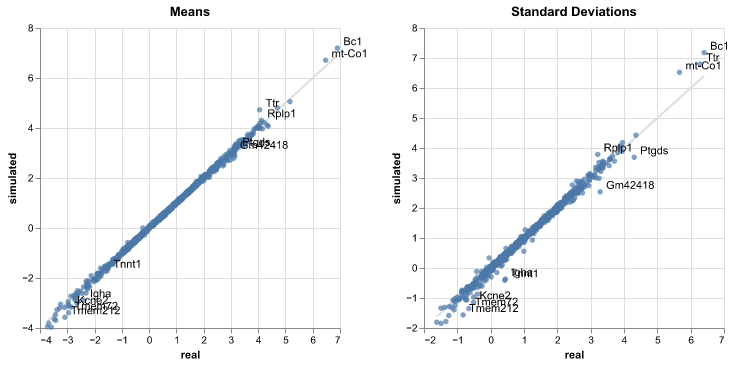

In [19]:
compare_moments(sce, sim.sample(), label_threshold=0.5)

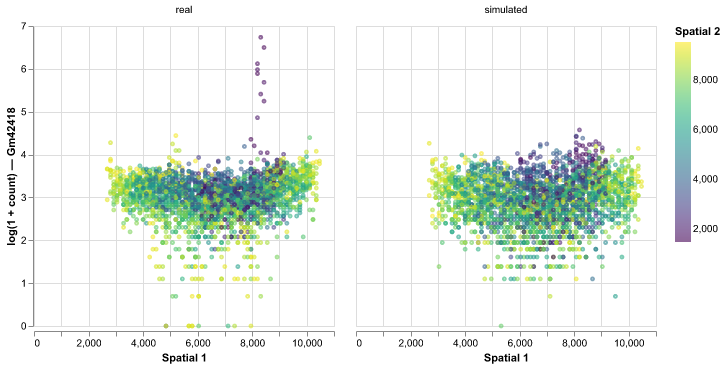

In [20]:
compare_spatial(sce, sim, "Gm42418")

Epoch 178/200, Loss: 1.7695, Val Loss: 1.7867


Estimating copula correlation: 100%|██████████| 3/3 [00:06<00:00,  2.20s/it]


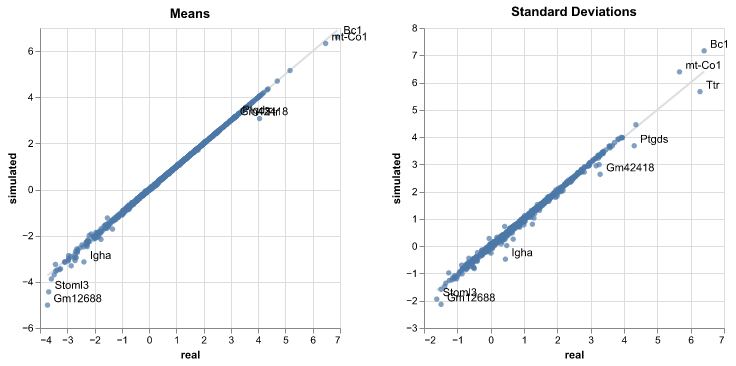

In [21]:
sim = PenalizedNegBinCopula("~ cell_type")
sim.fit(sce, max_epochs = 200)
compare_moments(sce, sim.sample(), label_threshold=0.5)

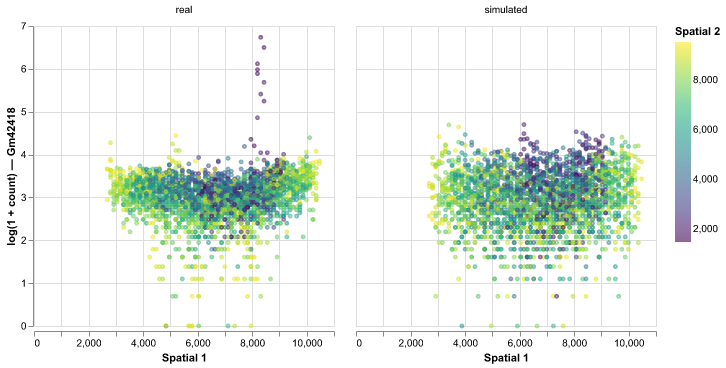

In [22]:
compare_spatial(sce, sim, "Gm42418")